# Lab 04 — Generating Text
### From next-token probabilities to controlled autoregressive decoding

**Language:** English · **Study time:** two sessions of 90 minutes · **Default device:** CPU

Lab 3 trained a 34,433-parameter causal Transformer. This lab turns its logits into generated English text. You will implement a transparent generation loop, compare sampling policies, verify a KV cache, derive speculative sampling, and measure weight-only quantization.

This independently authored lesson follows **Step 4** of FareedKhan-dev's repository. It continues the component-by-component, implementation-and-verification approach inspired by Stanford CS336. It is not an official Stanford assignment.

**Learning outcomes**
1. Explain why the last logit row predicts the next token.
2. Derive temperature, top-k, top-p, and min-p sampling.
3. Implement seeded generation with context cropping, EOT stopping, and a token budget.
4. Distinguish quality, distributional correctness, memory savings, and wall-clock speed.
5. Verify cached decoding, speculative correction, and int8 reconstruction on small examples.

**Deliverables from running this notebook**
- Generated samples with decoding configuration, seed, stop reason, and token-level traces.
- Distribution plots and sampling checks.
- KV-cache equivalence and speculative-decoding tests.
- Quantization error, model-storage, and timing measurements.

**Source map**
- [Step 4](https://github.com/FareedKhan-dev/train-llm-from-scratch#step-4-generating-text)
- [Sampling implementation](https://github.com/FareedKhan-dev/train-llm-from-scratch/blob/main/src/inference/sampling.py)
- [Generation CLI](https://github.com/FareedKhan-dev/train-llm-from-scratch/blob/main/scripts/generate_text.py)
- [Modern inference explanation](https://github.com/FareedKhan-dev/train-llm-from-scratch/blob/main/docs/modern/inference.md)
- [Speculative decoding](https://github.com/FareedKhan-dev/train-llm-from-scratch/blob/main/src/inference/speculative.py)
- [Int8 quantization](https://github.com/FareedKhan-dev/train-llm-from-scratch/blob/main/src/inference/quantize.py)
- [Modern model and cache rollover](https://github.com/FareedKhan-dev/train-llm-from-scratch/blob/main/src/models/modern/model.py)
- [Stanford CS336](https://cs336.stanford.edu/spring2025/)

Sources inspected on 14 November 2026. Sampling source blob: `e3ff9ee2e5b52fa780117cada234426ac897060b`. Speculative source blob: `08d117a48ef205a54084298b7ddf8ecbefa193e5`.

### Verified reference run

All 19 code cells completed on CPU with PyTorch 2.15.0+cpu. Saved outputs include 27 policy/prompt/seed sample records and two probability figures.

| Check | Observed result |
|---|---|
| Sampling parity with repository source | 360 valid parameter combinations matched |
| EOT, zero budget, context crop, mode restoration, local RNG | Passed |
| Full vs cached logits | Maximum absolute error 2.38e-6 |
| Cached vs recomputed greedy sequence | Exact token-ID match in the tested window |
| Speculative categorical correction | 20,000 samples agreed with target probabilities within the stated tolerance |
| Greedy block verification | Matched ordinary target decoding with both draft controls |
| Stored model tensors after int8 conversion | 137,732 bytes → 66,308 bytes |

These are checks on this small CPU model and its tested inputs. Quantized tensor size excludes runtime temporaries and file-format overhead. The generated samples include repetition and misspellings, which are discussed explicitly in Section 8.


## 1. Set up and select the Lab 3 checkpoint

Install `torch` and `matplotlib` in your notebook environment. In Jupyter or Colab, use `%pip install torch matplotlib` in a separate cell if needed.

Run Lab 3 first. It saves a `final.pt` checkpoint under `lab03_runs/<run-folder>/final.pt`. This lab automatically selects the most recently modified checkpoint in that folder. If you keep the checkpoint elsewhere, set `CHECKPOINT_PATH` to its path below.

The loader checks the saved tokenizer and reconstructs the model from its configuration. It supports the Lab 3 notebook checkpoint format. Repository checkpoints use a different format and should be loaded with the repository's own loader.

The default uses CPU and FP32. Lab 3's example model has a context of 24 **character tokens**, so a short prompt can use much of its context. Its output reflects the limited synthetic training distribution.


In [1]:
import copy
import json
import math
import statistics
import tempfile
import time
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F

torch.set_num_threads(1)
torch.manual_seed(42)
DEVICE = torch.device("cpu")
CHECKPOINT_PATH = None  # Optional: Path("path/to/lab03_runs/run_xxx/final.pt")
Path("lab04_runs").mkdir(exist_ok=True)
RUN_DIR = Path(tempfile.mkdtemp(prefix="run_", dir="lab04_runs"))
print("PyTorch:", torch.__version__, "| device:", DEVICE)
print("Outputs:", RUN_DIR)


PyTorch: 2.15.0+cpu | device: cpu
Outputs: /workspace/scratch/d20f4a09d498/lab04_runs/run_yjz4qc1m


## 2. Restore the classic Transformer and tokenizer

The definitions below reuse the model from Lab 2 and Lab 3. `forward(ids)` returns `(logits, loss)`. During inference, targets are omitted and gradients are unnecessary.

The lab tokenizer maps ASCII characters to IDs 0–127 and uses ID 128 for EOT. The numeric EOT ID is specific to this tokenizer. The repository's `r50k_base` tokenizer uses a different vocabulary and EOT ID.

Two inference settings have distinct roles: `eval()` selects evaluation behavior for modules such as dropout; `torch.inference_mode()` avoids autograd bookkeeping. The generation function will restore the model's prior training/evaluation mode when it finishes.


In [2]:
class MLP(nn.Module):
    def __init__(self, width):
        super().__init__()
        self.hidden = nn.Linear(width, 4 * width)
        self.proj = nn.Linear(4 * width, width)

    def forward(self, x):
        return self.proj(F.relu(self.hidden(x)))

def causal_attention(q, k, v):
    scores = q @ k.transpose(-2, -1) / math.sqrt(q.shape[-1])
    length = q.shape[-2]
    allowed = torch.ones(length, length, dtype=torch.bool, device=q.device).tril()
    weights = scores.masked_fill(~allowed, float("-inf")).softmax(dim=-1)
    return weights @ v, weights

class Head(nn.Module):
    def __init__(self, width, head_width):
        super().__init__()
        self.query = nn.Linear(width, head_width, bias=False)
        self.key = nn.Linear(width, head_width, bias=False)
        self.value = nn.Linear(width, head_width, bias=False)

    def forward(self, x):
        output, _ = causal_attention(self.query(x), self.key(x), self.value(x))
        return output

class MultiHeadAttention(nn.Module):
    def __init__(self, width, heads):
        super().__init__()
        if width % heads:
            raise ValueError("Embedding width must be divisible by head count.")
        self.heads = nn.ModuleList([Head(width, width // heads) for _ in range(heads)])
        self.proj = nn.Linear(width, width)

    def forward(self, x):
        return self.proj(torch.cat([head(x) for head in self.heads], dim=-1))

class Block(nn.Module):
    def __init__(self, width, heads):
        super().__init__()
        self.ln1 = nn.LayerNorm(width)
        self.attn = MultiHeadAttention(width, heads)
        self.ln2 = nn.LayerNorm(width)
        self.mlp = MLP(width)

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        return x + self.mlp(self.ln2(x))

class Transformer(nn.Module):
    def __init__(self, vocab_size, width, heads, context_length, layers):
        super().__init__()
        self.context_length = context_length
        self.token_embed = nn.Embedding(vocab_size, width)
        self.position_embed = nn.Embedding(context_length, width)
        self.blocks = nn.ModuleList([Block(width, heads) for _ in range(layers)])
        self.norm = nn.LayerNorm(width)
        self.lm_head = nn.Linear(width, vocab_size)

    def forward_hidden(self, ids):
        length = ids.shape[1]
        if not 1 <= length <= self.context_length:
            raise ValueError("Sequence length is outside the supported context.")
        positions = torch.arange(length, device=ids.device)
        hidden = self.token_embed(ids) + self.position_embed(positions)
        for block in self.blocks:
            hidden = block(hidden)
        return self.norm(hidden)

    def forward(self, ids, targets=None):
        logits = self.lm_head(self.forward_hidden(ids))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), targets.reshape(-1).long())
        return logits, loss


In [3]:
if CHECKPOINT_PATH is None:
    candidates = sorted(Path("lab03_runs").glob("*/final.pt"), key=lambda path: path.stat().st_mtime)
    if not candidates:
        raise FileNotFoundError(
            "No Lab 3 checkpoint found under lab03_runs/*/final.pt. "
            "Run Lab 3 first or set CHECKPOINT_PATH to your final.pt file."
        )
    checkpoint_path = candidates[-1]
else:
    checkpoint_path = Path(CHECKPOINT_PATH).expanduser()
    if not checkpoint_path.is_file():
        raise FileNotFoundError(f"Checkpoint does not exist: {checkpoint_path}")

checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
checkpoint_source = str(checkpoint_path)
expected_tokenizer = {"kind": "ascii-character", "vocab_size": 129, "eot_id": 128}
if checkpoint.get("format_version") != 1 or checkpoint.get("tokenizer") != expected_tokenizer:
    raise ValueError("Provide a compatible Lab 3 checkpoint with the ASCII tokenizer.")
config = checkpoint["config"]
VOCAB_SIZE, EOT_ID = 129, 128
WINDOW = config["context_length"]
model = Transformer(VOCAB_SIZE, config["width"], config["heads"], WINDOW, config["layers"]).to(DEVICE)
model.load_state_dict(checkpoint["model_state"], strict=True)
model.eval()

def encode_prompt(text):
    if not isinstance(text, str) or not text or not text.isascii():
        raise ValueError("Provide a nonempty ASCII prompt for this character tokenizer.")
    return torch.tensor([[ord(character) for character in text]], dtype=torch.long, device=DEVICE)

def decode_ids(ids, show_eot=False):
    pieces = []
    for token_id in ids:
        token_id = int(token_id)
        if token_id == EOT_ID:
            if show_eot:
                pieces.append("<EOT>")
        elif 0 <= token_id < 128:
            pieces.append(chr(token_id))
        else:
            raise ValueError("Token ID is outside the tokenizer vocabulary.")
    return "".join(pieces)

(RUN_DIR / "manifest.json").write_text(json.dumps({
    "checkpoint_source": checkpoint_source,
    "tokenizer": expected_tokenizer,
    "model_config": config,
    "completed_training_updates": checkpoint["completed_updates"],
    "torch_version": str(torch.__version__),
    "device": str(DEVICE),
}, indent=2))
print("Checkpoint:", checkpoint_source)
print("Completed training updates:", checkpoint["completed_updates"])
print("Context:", WINDOW, "characters | Parameters:", sum(p.numel() for p in model.parameters()))
assert decode_ids(encode_prompt("Anna")[0]) == "Anna"


Checkpoint: lab03_runs/run_pvg4r57e/final.pt
Completed training updates: 200
Context: 24 characters | Parameters: 34433


## 3. Understand the autoregressive loop

For a prompt $x_{1:m}$, generation samples a continuation one token at a time:

$$p(x_{m+1:m+n}\mid x_{1:m})=\prod_{j=1}^{n}p(x_{m+j}\mid x_{1:m+j-1}).$$

A forward pass produces `(batch, sequence, vocabulary)` logits. At position `t`, the model was trained to predict the token after position `t`. Therefore `logits[:, -1, :]` is the distribution for the next token after the current prefix.

| Operation | Shape for one prompt |
|---|---|
| Tokenize prompt | `(1, T)` |
| Forward pass | `(1, T, V)` |
| Select final logit row | `(1, V)` |
| Choose one token | `(1, 1)` |
| Append token | `(1, T+1)` |

**Worked example:** For prompt IDs `[10, 20, 30]`, only the row associated with token 30 supplies the next-token scores. Appending the chosen ID creates a new prefix for the following step.

**Exercise:** Explain why taking `argmax` over the sequence axis would be incorrect. Write the axis used by softmax and by token selection.


In [4]:
prompt_ids = encode_prompt("Anna")
with torch.inference_mode():
    all_logits, _ = model(prompt_ids)
next_logits = all_logits[:, -1, :]
probabilities = next_logits.softmax(dim=-1)
assert probabilities.shape == (1, VOCAB_SIZE)
assert torch.allclose(probabilities.sum(-1), torch.ones(1))
values, indices = probabilities.topk(8)
for token_id, probability in zip(indices[0].tolist(), values[0].tolist()):
    print(repr(decode_ids([token_id], show_eot=True)), f"{probability:.4f}")


' ' 0.5966
'd' 0.2522
'r' 0.0662
'n' 0.0342
't' 0.0161
'.' 0.0076
'a' 0.0046
'e' 0.0039


## 4. Temperature and greedy decoding

For temperature $\tau>0$,

$$p_i(\tau)=\frac{\exp(z_i/\tau)}{\sum_j\exp(z_j/\tau)}.$$

Temperature changes probability ratios: $p_i/p_j=\exp((z_i-z_j)/\tau)$. Smaller positive values concentrate probability on high-scoring tokens. Larger values spread it out. The ranking stays the same.

Greedy decoding selects $\arg\max_i z_i$ directly. It optimizes the next local choice, not the probability of the entire future sequence. We expose it with `greedy=True`. The lab rejects nonpositive temperatures for sampling; the repository instead clamps the temperature divisor to a small positive value.

**Calculation:** If two logits differ by 2, their probability ratio is $e^2$ at temperature 1 and $e^4$ at temperature 0.5.


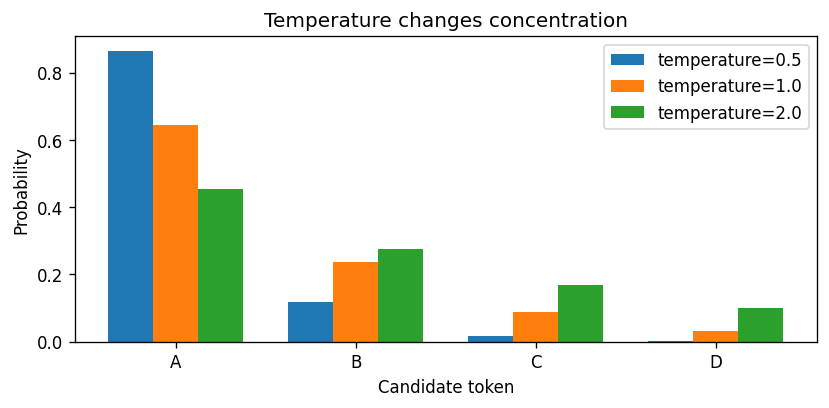

In [5]:
toy_logits = torch.tensor([[2.0, 1.0, 0.0, -1.0]])
fig, ax = plt.subplots(figsize=(7, 3.5))
positions = torch.arange(4).numpy()
for offset, temperature in enumerate((0.5, 1.0, 2.0)):
    probs = (toy_logits / temperature).softmax(-1)[0]
    ax.bar(positions + (offset - 1) * 0.25, probs.numpy(), width=0.25, label=f"temperature={temperature}")
ax.set(xticks=positions, xticklabels=["A", "B", "C", "D"], xlabel="Candidate token", ylabel="Probability", title="Temperature changes concentration")
ax.legend()
fig.tight_layout()
fig.savefig(RUN_DIR / "temperature.png", dpi=140)
plt.show()


## 5. Top-k, top-p, and min-p

The repository applies filters in this order: **temperature → top-k → top-p → min-p**. Each later probability calculation uses the tokens that survived earlier filters. Removed logits become $-\infty$, which yields zero probability after softmax.

| Filter | Rule | What stays fixed |
|---|---|---|
| Top-k | Keep scores at least as large as the kth-highest score | A score threshold based on rank |
| Top-p | Sort by probability and retain a prefix including the threshold-crossing token | A cumulative mass threshold |
| Min-p | Keep $p_i\ge\alpha\max_jp_j$ | A ratio to the largest probability |

For probabilities `[0.50, 0.25, 0.15, 0.10]`, top-k=2 keeps A and B. Top-p=0.70 also keeps A and B. Min-p=0.30 keeps A, B, and C because the threshold is 0.15.

The score-threshold top-k implementation can retain more than k tokens when scores tie. The repository's shifted `cumulative > top_p` mask includes the crossing token; at an exact cumulative-boundary equality it can retain an additional token. We preserve these implementation details below.

As in the repository, `top_k=0` disables top-k, and top-p/min-p values at 0 or 1 disable those filters. Use values strictly between 0 and 1 to enable either probability filter.

Top-p and min-p use probabilities after previous filters. Combining filters changes the experiment compared with testing each one separately.


In [6]:
def filter_logits(logits, temperature=1.0, top_k=None, top_p=None, min_p=None):
    if not math.isfinite(temperature) or temperature <= 0:
        raise ValueError("Sampling temperature must be finite and positive.")
    if logits.ndim != 2 or logits.shape[-1] < 1:
        raise ValueError("Expected logits with shape (batch, vocabulary).")
    if torch.isnan(logits).any() or torch.isposinf(logits).any() or not torch.isfinite(logits).any(dim=-1).all():
        raise ValueError("Each row needs at least one finite logit and no NaN/+inf.")
    if top_k is not None and (not isinstance(top_k, int) or isinstance(top_k, bool) or top_k < 0):
        raise ValueError("top_k must be a nonnegative integer or None.")
    for value, name in ((top_p, "top_p"), (min_p, "min_p")):
        if value is not None and (not math.isfinite(value) or not 0 <= value <= 1):
            raise ValueError(f"{name} must lie in [0, 1] or be None.")
    filtered = logits.float() / temperature
    if top_k is not None and top_k > 0:
        k = min(top_k, filtered.shape[-1])
        threshold = filtered.topk(k, dim=-1).values[:, -1:]
        filtered = filtered.masked_fill(filtered < threshold, float("-inf"))
    if top_p is not None and 0 < top_p < 1:
        sorted_logits, sorted_indices = filtered.sort(dim=-1, descending=True)
        cumulative = sorted_logits.softmax(-1).cumsum(-1)
        remove = cumulative > top_p
        remove[:, 1:] = remove[:, :-1].clone()
        remove[:, 0] = False
        remove_original_order = torch.zeros_like(remove).scatter(1, sorted_indices, remove)
        filtered = filtered.masked_fill(remove_original_order, float("-inf"))
    if min_p is not None and 0 < min_p < 1:
        probabilities = filtered.softmax(-1)
        threshold = min_p * probabilities.max(-1, keepdim=True).values
        filtered = filtered.masked_fill(probabilities < threshold, float("-inf"))
    return filtered

def choose_token(logits, generator=None, greedy=False, **sampling):
    if greedy:
        return logits.argmax(dim=-1, keepdim=True)
    probabilities = filter_logits(logits, **sampling).softmax(-1)
    return torch.multinomial(probabilities, 1, generator=generator)

example_logits = torch.tensor([[0.50, 0.25, 0.15, 0.10]]).log()
assert torch.isfinite(filter_logits(example_logits, top_k=2)).tolist() == [[True, True, False, False]]
assert torch.isfinite(filter_logits(example_logits, top_p=0.7)).tolist() == [[True, True, False, False]]
# Use a threshold away from a floating-point equality boundary for the numerical test.
assert torch.isfinite(filter_logits(example_logits, min_p=0.29)).tolist() == [[True, True, True, False]]
assert torch.isfinite(filter_logits(torch.zeros(1, 4), top_k=2)).sum() == 4
assert torch.isfinite(filter_logits(example_logits, top_p=0.01)).sum() == 1
assert choose_token(example_logits, greedy=True).item() == 0
assert torch.equal(example_logits, torch.tensor([[0.50, 0.25, 0.15, 0.10]]).log())
print("Filter support, ties, minimum support, and greedy checks passed.")


Filter support, ties, minimum support, and greedy checks passed.


## 6. Implement the generation loop

Our function handles one unpadded prompt at a time. It returns both the full token sequence and the continuation, plus a trace of each choice. `max_new_tokens` counts newly appended tokens, including a sampled EOT. If EOT is sampled and stopping is enabled, it remains in the returned token IDs and is omitted from ordinary decoded text.

The classic model recomputes the latest context window on each step. Once the sequence exceeds the window, older tokens remain in the displayed output but leave the model's input. Learned positions restart at zero within that cropped window. This follows the classic repository generation strategy.

The repository's basic loop uses a fixed generation budget. EOT stopping, explicit argument checks, per-step traces, and local seeded randomness are teaching additions in this notebook. An empty prompt is rejected because this tokenizer/model was not trained with a separate beginning-of-sequence token.


In [7]:
@torch.inference_mode()
def generate(model, prompt_ids, max_new_tokens=60, *, seed=42, greedy=False,
             temperature=1.0, top_k=None, top_p=None, min_p=None, stop_on_eot=True,
             context_window=None, record_trace=True):
    if prompt_ids.ndim != 2 or prompt_ids.shape[0] != 1 or prompt_ids.shape[1] == 0:
        raise ValueError("Provide one nonempty prompt with shape (1, length).")
    if prompt_ids.dtype != torch.long or ((prompt_ids < 0) | (prompt_ids >= VOCAB_SIZE)).any():
        raise ValueError("Prompt IDs must be valid torch.long vocabulary indices.")
    if not isinstance(max_new_tokens, int) or isinstance(max_new_tokens, bool) or max_new_tokens < 0:
        raise ValueError("max_new_tokens must be a nonnegative integer.")
    window = model.context_length if context_window is None else context_window
    if not isinstance(window, int) or isinstance(window, bool) or not 1 <= window <= model.context_length:
        raise ValueError("Context window must fit the model's trained position table.")
    sampling = dict(temperature=temperature, top_k=top_k, top_p=top_p, min_p=min_p)
    if not greedy:
        filter_logits(torch.zeros(1, VOCAB_SIZE, device=prompt_ids.device), **sampling)
    generator = torch.Generator(device=prompt_ids.device).manual_seed(seed)
    output = prompt_ids.clone()
    start_length = output.shape[1]
    trace = []
    stop_reason = "max_new_tokens"
    was_training = model.training
    model.eval()
    try:
        for step in range(max_new_tokens):
            visible = output[:, -window:]
            logits, _ = model(visible)
            logits = logits[:, -1, :].float()
            selected = choose_token(logits, generator=generator, greedy=greedy, **sampling)
            token_id = int(selected.item())
            if record_trace:
                policy_probs = F.one_hot(selected[:, 0], VOCAB_SIZE).float() if greedy else filter_logits(logits, **sampling).softmax(-1)
                trace.append({"step": step + 1, "token_id": token_id,
                              "token": decode_ids([token_id], show_eot=True),
                              "visible_tokens": visible.shape[1],
                              "raw_probability": logits.softmax(-1)[0, token_id].item(),
                              "sampling_probability": policy_probs[0, token_id].item()})
            output = torch.cat([output, selected], dim=1)
            if stop_on_eot and token_id == EOT_ID:
                stop_reason = "eot"
                break
    finally:
        model.train(was_training)
    continuation = output[:, start_length:]
    return {"ids": output, "continuation_ids": continuation, "trace": trace,
            "stop_reason": stop_reason, "generated_tokens": continuation.shape[1]}

result = generate(model, encode_prompt("Anna"), max_new_tokens=60, seed=42, temperature=0.8, top_p=0.9)
print("Full text:", repr(decode_ids(result["ids"][0])))
print("Continuation:", repr(decode_ids(result["continuation_ids"][0])))
print("Stop:", result["stop_reason"], "| new tokens:", result["generated_tokens"])
for row in result["trace"][:8]:
    print(row)


Full text: 'Anna boo and a a wend wend arentoo a toowed the a and a ared a a'
Continuation: ' boo and a a wend wend arentoo a toowed the a and a ared a a'
Stop: max_new_tokens | new tokens: 60
{'step': 1, 'token_id': 32, 'token': ' ', 'visible_tokens': 4, 'raw_probability': 0.5966160893440247, 'sampling_probability': 0.7457835078239441}
{'step': 2, 'token_id': 98, 'token': 'b', 'visible_tokens': 5, 'raw_probability': 0.086556576192379, 'sampling_probability': 0.0841091200709343}
{'step': 3, 'token_id': 111, 'token': 'o', 'visible_tokens': 6, 'raw_probability': 0.3191162049770355, 'sampling_probability': 0.3941974937915802}
{'step': 4, 'token_id': 111, 'token': 'o', 'visible_tokens': 7, 'raw_probability': 0.28757303953170776, 'sampling_probability': 0.3921467363834381}
{'step': 5, 'token_id': 32, 'token': ' ', 'visible_tokens': 8, 'raw_probability': 0.3019525706768036, 'sampling_probability': 0.4174977242946625}
{'step': 6, 'token_id': 97, 'token': 'a', 'visible_tokens': 9, 'raw_probabi

## 7. Check stopping, budgets, mode restoration, and randomness

Use deterministic fake logits to test the loop independently of model quality. A model that always selects EOT should stop after exactly one appended token. A zero-token budget should return the prompt unchanged. Long prompts should be cropped before the forward pass.

A local `torch.Generator` keeps generation from consuming the global sampling RNG. A fixed seed reproduces a sample under the same implementation and environment. Changing a decoding policy can change which random draws select which tokens, so a common seed alone does not make token-by-token comparisons identical.


In [8]:
class AlwaysEOT(nn.Module):
    context_length = WINDOW
    def forward(self, ids):
        assert 1 <= ids.shape[1] <= self.context_length
        logits = torch.full((*ids.shape, VOCAB_SIZE), -100.0, device=ids.device)
        logits[..., EOT_ID] = 100.0
        return logits, None

fake_model = AlwaysEOT().train()
prompt = encode_prompt("A")
one = generate(fake_model, prompt, max_new_tokens=5, greedy=True)
assert one["generated_tokens"] == 1 and one["stop_reason"] == "eot"
assert one["ids"][0, -1].item() == EOT_ID
assert fake_model.training
zero = generate(fake_model, prompt, max_new_tokens=0)
assert torch.equal(zero["ids"], prompt)
fixed = generate(fake_model, prompt, max_new_tokens=3, greedy=True, stop_on_eot=False)
assert fixed["generated_tokens"] == 3
long_prompt = encode_prompt("A" * (WINDOW + 10))
assert generate(fake_model, long_prompt, max_new_tokens=1, greedy=True)["trace"][0]["visible_tokens"] == WINDOW
before_rng = torch.get_rng_state().clone()
first = generate(model, encode_prompt("Ben"), max_new_tokens=30, seed=7, top_k=10)
second = generate(model, encode_prompt("Ben"), max_new_tokens=30, seed=7, top_k=10)
assert torch.equal(first["ids"], second["ids"])
assert torch.equal(before_rng, torch.get_rng_state())
for bad_prompt in ("", "café"):
    try:
        encode_prompt(bad_prompt)
    except ValueError:
        pass
    else:
        raise AssertionError("Expected a rejected prompt.")
print("EOT, budget, cropping, mode restoration, and reproducibility checks passed.")


EOT, budget, cropping, mode restoration, and reproducibility checks passed.


## 8. Compare decoding policies on the same checkpoint

The experiment varies the decoding rule while holding the checkpoint and prompts fixed. Print several seeds for stochastic policies, and preserve raw text with `repr` so any control characters are visible. The model's ASCII vocabulary includes characters that were not present in training; high temperatures can assign them noticeable sampling probability.

Read samples for recognizable training patterns, spelling, repetition, and completion of a sentence. Lower temperature or stronger filtering may produce cleaner local choices while reducing diversity. Sampling settings cannot supply knowledge that the small model never learned.

**Interpreting the reference run:** The packaged model still produces misspellings and repetition. Lab 3 validation used teacher-forced prefixes from the corpus, whereas free-running generation feeds the model its own sampled outputs. An early mistake changes later contexts, and a 24-character window provides limited history. Low token-level validation loss on this synthetic distribution does not establish coherent long-form generation. Preserve the observed samples rather than editing them into better sentences.

A base model continues its prompt. Giving it a chat-style instruction does not establish instruction-following behavior; that is a later training stage.


In [9]:
policies = {
    "greedy": {"greedy": True},
    "temperature_1.0": {"temperature": 1.0},
    "top_k_8": {"temperature": 0.8, "top_k": 8},
    "top_p_0.9": {"temperature": 0.8, "top_p": 0.9},
    "min_p_0.1": {"temperature": 0.8, "min_p": 0.1},
}
samples = []
for prompt_text in ("Anna", "The", "Ben went to the "):
    for policy_name, options in policies.items():
        for seed in ((7,) if options.get("greedy") else (7, 19)):
            sample = generate(model, encode_prompt(prompt_text), max_new_tokens=70, seed=seed, **options)
            record = {"prompt": prompt_text, "policy": policy_name, "options": options, "seed": seed,
                      "text": decode_ids(sample["ids"][0]), "generated_tokens": sample["generated_tokens"],
                      "stop_reason": sample["stop_reason"], "trace": sample["trace"]}
            samples.append(record)
            print(f"{prompt_text!r} | {policy_name:16} | seed={seed:2} | {record['stop_reason']:14} | {record['text']!r}")
(RUN_DIR / "samples.json").write_text(json.dumps(samples, indent=2))


'Anna' | greedy           | seed= 7 | eot            | 'Anna ary went t t to the are are arend ary.'
'Anna' | temperature_1.0  | seed= 7 | eot            | 'Anna wery.'
'Anna' | temperature_1.0  | seed=19 | eot            | 'Annad biy.'
'Anna' | top_k_8          | seed= 7 | eot            | 'Anna wend.'
'Anna' | top_k_8          | seed=19 | eot            | 'Annad went tir.'
'Anna' | top_p_0.9        | seed= 7 | eot            | 'Anna wend t to thar.'
'Anna' | top_p_0.9        | seed=19 | max_new_tokens | 'Annad went to to the ared and a a a a ara a wara antound the a re ara arar'
'Anna' | min_p_0.1        | seed= 7 | eot            | 'Anna wend t to thar.'
'Anna' | min_p_0.1        | seed=19 | max_new_tokens | 'Annad went to to the ared and a a a a ara a wara antound the a aryed a ar.'
'The' | greedy           | seed= 7 | eot            | 'The arend a a ad a a a a ary.'
'The' | temperature_1.0  | seed= 7 | eot            | 'The Gory.Qrnt aral.'
'The' | temperature_1.0  | seed=19 | eot

## 9. Inspect the probability distribution at one step

Sequence-level text comparisons mix many decisions. To isolate a decoding setting, inspect one shared logit vector. After filtering, surviving probabilities are renormalized to sum to one.

The trace's `raw_probability` comes from the model's temperature-1 distribution. `sampling_probability` comes from the actual policy after temperature and filtering. For greedy decoding, the policy probability is 1 for its selected token even when the model's probability is lower.

**Exercise:** Find a token whose sampling probability increases after top-k filtering. Explain the increase using renormalization, without claiming the model's weights changed.


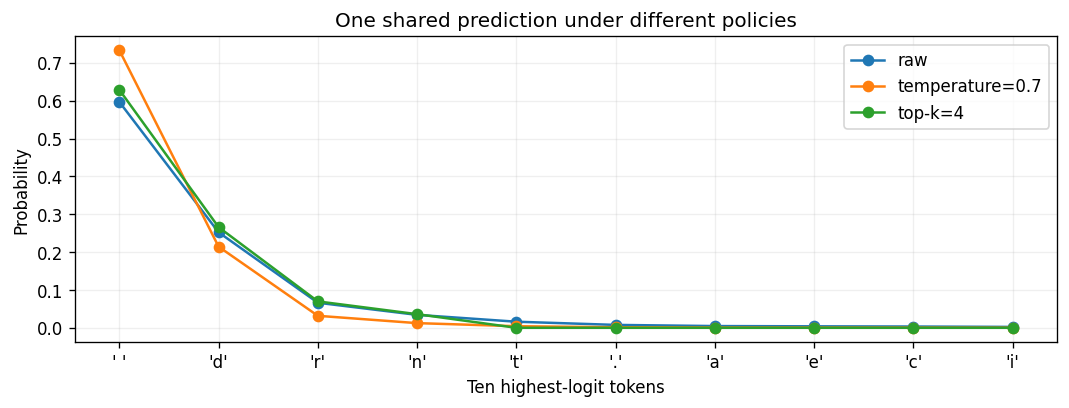

In [10]:
with torch.inference_mode():
    inspection_logits = model(encode_prompt("Anna"))[0][:, -1, :]
selected_ids = inspection_logits[0].topk(10).indices
fig, ax = plt.subplots(figsize=(9, 3.5))
for label, options in (("raw", {}), ("temperature=0.7", {"temperature": 0.7}), ("top-k=4", {"top_k": 4})):
    distribution = filter_logits(inspection_logits, **options).softmax(-1)[0]
    ax.plot(range(10), distribution[selected_ids].numpy(), marker="o", label=label)
ax.set(xticks=range(10), xticklabels=[repr(decode_ids([i], show_eot=True)) for i in selected_ids.tolist()],
       xlabel="Ten highest-logit tokens", ylabel="Probability", title="One shared prediction under different policies")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(RUN_DIR / "next_token_policies.png", dpi=140)
plt.show()


## 10. Prefill, decode, and KV caching

For a fixed prefix and unchanged positions, earlier layers' keys and values do not depend on later tokens because attention is causal. Save those tensors once during **prefill**, then process only the newest token during **decode**.

A conventional cache stores approximately $2LBTH_{kv}d$ elements. The factor 2 accounts for keys and values. A new query still attends to the cached sequence. For a growing sequence, caching makes projection/MLP work linear in processed tokens, while total full-attention pairwise work remains quadratic. Caching does not make all attention work linear.

The following teaching implementation adds a cache to our classic model. It supports a prefix that fits inside its trained context. Each block stores one `(K, V)` pair per head. Queries use absolute position offsets to construct the mask correctly when query and key lengths differ.

At rollover, the classic model's cropped-window positions change. Reusing old cached tensors after those position changes would be incorrect. The regular generator recomputes the window. The repository's modern generator instead resets and prefills the latest half-window when its cache is full; after that reset, its available context differs from a full-window recomputation.


In [11]:
@torch.inference_mode()
def cached_forward(model, new_ids, cache=None):
    if cache is None:
        cache = [[None for _ in block.attn.heads] for block in model.blocks]
        offset = 0
    else:
        offset = cache[0][0][0].shape[1]
    count = new_ids.shape[1]
    if offset + count > model.context_length:
        raise ValueError("Cache exceeds the trained context; reset and prefill explicitly.")
    positions = torch.arange(offset, offset + count, device=new_ids.device)
    hidden = model.token_embed(new_ids) + model.position_embed(positions)
    updated_cache = []
    for block_index, block in enumerate(model.blocks):
        normalized = block.ln1(hidden)
        head_outputs, layer_cache = [], []
        for head_index, head in enumerate(block.attn.heads):
            query = head.query(normalized)
            key, value = head.key(normalized), head.value(normalized)
            previous = cache[block_index][head_index]
            if previous is not None:
                key = torch.cat([previous[0], key], dim=1)
                value = torch.cat([previous[1], value], dim=1)
            scores = query @ key.transpose(-2, -1) / math.sqrt(query.shape[-1])
            query_positions = torch.arange(offset, offset + count, device=new_ids.device)[:, None]
            key_positions = torch.arange(key.shape[1], device=new_ids.device)[None, :]
            weights = scores.masked_fill(key_positions > query_positions, float("-inf")).softmax(-1)
            head_outputs.append(weights @ value)
            layer_cache.append((key, value))
        hidden = hidden + block.attn.proj(torch.cat(head_outputs, dim=-1))
        hidden = hidden + block.mlp(block.ln2(hidden))
        updated_cache.append(layer_cache)
    return model.lm_head(model.norm(hidden)), updated_cache

check_ids = encode_prompt("Anna went to ")
with torch.inference_mode():
    full_logits = model(check_ids)[0]
    prefix_logits, cache = cached_forward(model, check_ids[:, :4])
    pieces = [prefix_logits]
    for position in range(4, check_ids.shape[1]):
        token_logits, cache = cached_forward(model, check_ids[:, position:position + 1], cache)
        pieces.append(token_logits)
    cached_logits = torch.cat(pieces, dim=1)
cache_error = (full_logits - cached_logits).abs().max().item()
assert torch.allclose(full_logits, cached_logits, atol=2e-5, rtol=1e-5)
cache_bytes = sum(t.numel() * t.element_size() for layer in cache for pair in layer for t in pair)
print("Maximum full-vs-cached logit error:", cache_error)
print("Actual K/V storage bytes:", cache_bytes)


Maximum full-vs-cached logit error: 2.384185791015625e-06
Actual K/V storage bytes: 6656


## 11. Verify cached greedy generation

Use a short continuation that stays inside the context window. Both implementations use the same positions and attention history, so greedy outputs should agree for this test. Disable EOT stopping to compare exactly the requested number of tokens.

The cached function below is intentionally bounded to one window. The general generator in Section 6 supports longer sequences using explicit recomputation.


In [12]:
@torch.inference_mode()
def cached_greedy(model, ids, max_new_tokens):
    if max_new_tokens < 0 or ids.shape[1] + max_new_tokens > model.context_length:
        raise ValueError("This demonstration must fit inside one context window.")
    output = ids.clone()
    if max_new_tokens == 0:
        return output
    logits, cache = cached_forward(model, output)
    for step in range(max_new_tokens):
        token = logits[:, -1, :].argmax(-1, keepdim=True)
        output = torch.cat([output, token], dim=1)
        if step + 1 < max_new_tokens:
            logits, cache = cached_forward(model, token, cache)
    return output

short_prompt = encode_prompt("Anna")
plain_ids = generate(model, short_prompt, 12, greedy=True, stop_on_eot=False, record_trace=False)["ids"]
cached_ids = cached_greedy(model, short_prompt, 12)
assert torch.equal(plain_ids, cached_ids)
print("Cached and recomputed greedy IDs agree:", repr(decode_ids(cached_ids[0], show_eot=True)))


Cached and recomputed greedy IDs agree: 'Anna ary went t '


## 12. Derive speculative sampling

A cheap draft proposes token $x$ from $q$. The target would sample from $p$. Accept the draft token with probability

$$a(x)=\min(1,p(x)/q(x)).$$

If it is rejected, sample from the normalized positive residual $r(x)\propto\max(p(x)-q(x),0)$. The accepted probability mass at token $x$ is $\min(p(x),q(x))$. The residual contributes $\max(p(x)-q(x),0)$. Their sum is $p(x)$.

For blocks of proposals, verify each in sequence and stop at the first rejection. If all proposals are accepted, draw a bonus token from the target's next distribution. Both models must share the same tokenizer/ID meanings. Use the actual normalized proposal and target distributions after their filters in the acceptance rule.

**Exactness condition:** Each target probability must correspond to the same prefix/context as ordinary target decoding. The repository's current speculative implementation explicitly notes that its cropped multi-token verification can change that context when the window overflows. Its equality guarantee therefore applies while the required text fits in the window. A shared random seed also does not imply identical sampled sequences, because speculative sampling consumes random draws differently.

**Worked example:** Let $p=[0.6,0.3,0.1]$ and $q=[0.2,0.5,0.3]$. Accepted mass is `[0.2,0.3,0.1]`; total rejection probability is 0.4, and all residual mass belongs to token A.


In [13]:
p = torch.tensor([0.6, 0.3, 0.1])
q = torch.tensor([0.2, 0.5, 0.3])
accepted_mass = torch.minimum(p, q)
residual = (p - q).clamp_min(0)
assert torch.allclose(accepted_mass + residual, p)
assert torch.allclose(residual.sum(), 1 - accepted_mass.sum())

generator = torch.Generator().manual_seed(42)
trials = 20000
proposals = torch.multinomial(q, trials, replacement=True, generator=generator)
accept = torch.rand(trials, generator=generator) < (p[proposals] / q[proposals]).clamp_max(1)
outputs = proposals.clone()
outputs[~accept] = torch.multinomial(residual / residual.sum(), int((~accept).sum()), replacement=True, generator=generator)
observed = torch.bincount(outputs, minlength=3).float() / trials
assert (observed - p).abs().max() < 0.02
print("Target probabilities:", p.tolist())
print("Observed speculative frequencies:", observed.tolist())
print("Acceptance frequency:", accept.float().mean().item())


Target probabilities: [0.6000000238418579, 0.30000001192092896, 0.10000000149011612]
Observed speculative frequencies: [0.6002500057220459, 0.30125001072883606, 0.09849999845027924]
Acceptance frequency: 0.599049985408783


## 13. Implement block verification for greedy decoding

Greedy speculative decoding accepts a proposed token exactly when it equals the target's argmax for that prefix. At the first mismatch, append the target's argmax and discard the remaining proposals. One target forward pass over the prompt plus proposals supplies all verification rows.

This exercise uses a smaller randomly initialized draft with the same tokenizer. It is expected to be a poor draft. A second case uses the target itself as a draft to expose the best-case acceptance behavior. The latter is an algorithm check, not a cheap draft or a speed optimization.

The implementation below supports one prompt and requires the full generated sequence to fit within the target window. It counts model calls rather than claiming a speedup. The repository provides the full stochastic block algorithm.


In [14]:
@torch.inference_mode()
def speculative_greedy(target, draft, ids, max_new_tokens, block_size=4):
    if ids.shape[0] != 1 or ids.shape[1] == 0 or block_size < 1 or max_new_tokens < 0:
        raise ValueError("Use one nonempty prompt and nonnegative budget with positive block size.")
    if ids.shape[1] + max_new_tokens > target.context_length:
        raise ValueError("Verification must fit in the target context.")
    output = ids.clone()
    start_length = output.shape[1]
    stats = {"proposed": 0, "accepted": 0, "target_calls": 0, "draft_calls": 0}
    while output.shape[1] - start_length < max_new_tokens:
        remaining = max_new_tokens - (output.shape[1] - start_length)
        proposal_count = min(block_size, remaining)
        proposed_prefix = output.clone()
        guesses = []
        for _ in range(proposal_count):
            draft_logits = draft(proposed_prefix[:, -draft.context_length:])[0][:, -1, :]
            guess = draft_logits.argmax(-1, keepdim=True)
            guesses.append(guess)
            proposed_prefix = torch.cat([proposed_prefix, guess], dim=1)
            stats["draft_calls"] += 1
        stats["proposed"] += proposal_count
        target_logits = target(proposed_prefix)[0]
        prefix_length = output.shape[1]
        verified = target_logits[:, prefix_length - 1:prefix_length + proposal_count, :].argmax(-1)
        stats["target_calls"] += 1
        rejected = False
        for index, guess in enumerate(guesses):
            expected = verified[:, index:index + 1]
            if torch.equal(guess, expected):
                output = torch.cat([output, guess], dim=1)
                stats["accepted"] += 1
            else:
                output = torch.cat([output, expected], dim=1)
                rejected = True
                break
        if not rejected and output.shape[1] - start_length < max_new_tokens:
            output = torch.cat([output, verified[:, proposal_count:proposal_count + 1]], dim=1)
    return output, stats

with torch.random.fork_rng():
    torch.manual_seed(3)
    draft = Transformer(VOCAB_SIZE, 16, 2, WINDOW, 1).eval()
for label, draft_model in (("small random draft", draft), ("target-as-draft control", model)):
    speculative_ids, stats = speculative_greedy(model, draft_model, short_prompt, 12)
    assert torch.equal(speculative_ids, plain_ids)
    print(label, stats, "| output:", repr(decode_ids(speculative_ids[0], show_eot=True)))


small random draft {'proposed': 42, 'accepted': 0, 'target_calls': 12, 'draft_calls': 42} | output: 'Anna ary went t '
target-as-draft control {'proposed': 10, 'accepted': 10, 'target_calls': 3, 'draft_calls': 10} | output: 'Anna ary went t '


## 14. Int8 weight-only quantization

For row $r$ of a linear weight matrix,

$$s_r=\max_j|W_{rj}|/127,\qquad Q_{rj}=\mathrm{round}(W_{rj}/s_r),\qquad\widehat W_{rj}=s_rQ_{rj}.$$

A small positive clamp handles an all-zero row. Store $Q$ as int8 and one FP32 scale per output row. A matrix with shape $(m,n)$ changes from $4mn$ weight bytes to approximately $mn+4m$ bytes, before bias and serialization overhead.

The repository dequantizes weights for each forward call and then uses a floating-point matrix multiplication. Stored linear weights become smaller, but dequantization adds work and temporary memory. Whole-model memory savings depend on how much of the model is in those linear weights. Embeddings, normalization, and the output head remain in FP32 in our default conversion, matching the repository's skip rule for `lm_head`.

**Exercise:** For a 128×128 FP32 weight matrix, compute original and quantized weight-plus-scale bytes. Expected values are 65,536 and 16,896 bytes.


In [15]:
class Int8Linear(nn.Module):
    def __init__(self, linear):
        super().__init__()
        weight = linear.weight.detach().float()
        scale = weight.abs().amax(dim=1, keepdim=True).clamp_min(1e-8) / 127
        self.register_buffer("quantized_weight", (weight / scale).round().clamp(-127, 127).to(torch.int8))
        self.register_buffer("scale", scale)
        self.register_buffer("bias", None if linear.bias is None else linear.bias.detach().clone())

    def forward(self, x):
        weight = (self.quantized_weight.float() * self.scale).to(x.dtype)
        bias = None if self.bias is None else self.bias.to(x.dtype)
        return F.linear(x, weight, bias)

def quantize_model(original):
    result = copy.deepcopy(original).eval()
    for parent in list(result.modules()):
        for name, child in list(parent.named_children()):
            if isinstance(child, nn.Linear) and name != "lm_head":
                setattr(parent, name, Int8Linear(child))
    return result

def tensor_storage_bytes(model):
    return sum(t.numel() * t.element_size() for t in list(model.parameters()) + list(model.buffers()))

quantized_model = quantize_model(model)
probe = encode_prompt("Anna went to the park.")
with torch.inference_mode():
    fp_logits = model(probe)[0]
    int8_logits = quantized_model(probe)[0]
    max_logit_error = (fp_logits - int8_logits).abs().max().item()
    mean_logit_error = (fp_logits - int8_logits).abs().mean().item()
    argmax_agreement = (fp_logits.argmax(-1) == int8_logits.argmax(-1)).float().mean().item()
quantization_metrics = {"fp32_tensor_bytes": tensor_storage_bytes(model),
                        "int8_tensor_bytes": tensor_storage_bytes(quantized_model),
                        "max_logit_error": max_logit_error, "mean_logit_error": mean_logit_error,
                        "argmax_agreement_on_probe": argmax_agreement}
assert quantization_metrics["int8_tensor_bytes"] < quantization_metrics["fp32_tensor_bytes"]
assert torch.isfinite(int8_logits).all()
print(json.dumps(quantization_metrics, indent=2))
quantized_sample = generate(quantized_model, encode_prompt("Anna"), 60, greedy=True)
print("Quantized greedy text:", repr(decode_ids(quantized_sample["ids"][0])))


{
  "fp32_tensor_bytes": 137732,
  "int8_tensor_bytes": 66308,
  "max_logit_error": 0.01642519235610962,
  "mean_logit_error": 0.0026309541426599026,
  "argmax_agreement_on_probe": 1.0
}
Quantized greedy text: 'Anna ary went t t to the are are arend ary.'


## 15. Measure latency fairly

Warm up the functions, use a fixed prompt and fixed generation budget, and disable EOT stopping for timing. Otherwise one method could appear faster because it emitted fewer tokens. Report median elapsed time across repeats. This benchmark is CPU-only and deliberately short enough to avoid cache rollover.

The uncached baseline includes the general generator's validation and local-generator setup. The specialized cached implementation has less Python bookkeeping. These small CPU timings describe this notebook's functions rather than an isolated kernel speedup. GPU timing would additionally require synchronization.

For a production study, separate time-to-first-token, subsequent decode latency, prefill cost, memory footprint, and batch effects. Count target calls for speculative decoding and also measure draft costs. Fewer target calls alone do not guarantee lower wall-clock time.


In [16]:
def benchmark(function, repeats=7, tokens=12):
    function()
    elapsed = []
    for _ in range(repeats):
        start = time.perf_counter()
        function()
        elapsed.append(time.perf_counter() - start)
    median_seconds = statistics.median(elapsed)
    return {"median_seconds": median_seconds, "tokens_per_second": tokens / median_seconds}

benchmarks = {
    "classic_recompute": benchmark(lambda: generate(model, short_prompt, 12, greedy=True, stop_on_eot=False, record_trace=False)),
    "classic_cached": benchmark(lambda: cached_greedy(model, short_prompt, 12)),
    "int8_recompute": benchmark(lambda: generate(quantized_model, short_prompt, 12, greedy=True, stop_on_eot=False, record_trace=False)),
}
print(json.dumps(benchmarks, indent=2))
(RUN_DIR / "inference_metrics.json").write_text(json.dumps({"quantization": quantization_metrics, "benchmarks": benchmarks, "cache_max_logit_error": cache_error}, indent=2))


{
  "classic_recompute": {
    "median_seconds": 0.00549118300000373,
    "tokens_per_second": 2185.321450767867
  },
  "classic_cached": {
    "median_seconds": 0.005544832000055067,
    "tokens_per_second": 2164.177381727855
  },
  "int8_recompute": {
    "median_seconds": 0.0076255839999248565,
    "tokens_per_second": 1573.6499657099378
  }
}


## 16. Run the corresponding repository commands

The repository loader rebuilds the architecture, tokenizer, and trained context from its checkpoint. Use a checkpoint created by the repository trainer with these commands. Our Lab 3 teaching checkpoint uses a different schema.

```bash
python scripts/generate_text.py --model_path models/tiny.pt --input_text "Once upon a time" --max_new_tokens 100
python scripts/generate_text.py --model_path models/tiny.pt --temperature 0.7 --top_k 40 --num_samples 3 --seed 42
python scripts/generate_text.py --model_path models/tiny.pt --top_k 0 --top_p 0.9 --seed 42
python scripts/generate_text.py --model_path models/tiny.pt --top_k 0 --min_p 0.05 --seed 42
python scripts/generate_text.py --model_path models/tiny.pt --int8
python scripts/generate_text.py --model_path models/student.pt --draft_model models/tiny.pt --draft_k 4
```

The CLI defaults to `top_k=50`. Set `--top_k 0` when isolating top-p or min-p. It supports `--seed`, but its ordinary path does not expose the notebook's explicit greedy flag. The sampling module has `sample_next_token(..., greedy=True)` for direct Python use.

The draft checkpoint must have the same tokenizer specification as the target. The current script checks that condition. Keep the speculative source's finite-context limitation in mind when designing an equality test.

The modern generator uses caching by default; the classic generator recomputes its visible window. Within a compatible unoverflowed prefix, cached and full-forward predictions can be checked for equivalence. After the modern generator's half-window cache reset, compare against a baseline with that same context policy.


## 17. Independent exercises

Complete the functions below and enable `RUN_EXERCISES`. Core demonstrations run without completing these starters.

1. **Temperature distribution:** implement stable softmax of `logits / temperature`. Reject nonpositive temperature.
2. **Min-p mask:** return a Boolean mask with the same shape as a supplied probability tensor, using a cutoff strictly between 0 and 1.
3. **Speculative residual:** normalize the positive part of `p-q`. If it is identically zero, return zeros to indicate that the rejection branch has zero probability.

**Written exercise:** Describe a case where top-k=2 retains more than two tokens in this implementation. Explain how to change the algorithm if exactly k indices are required.


In [17]:
def student_temperature_distribution(logits, temperature):
    raise NotImplementedError

def student_min_p_mask(probabilities, cutoff):
    raise NotImplementedError

def student_residual(p, q):
    raise NotImplementedError

def check_exercises(temperature_fn, mask_fn, residual_fn):
    logits = torch.tensor([[1000.0, 999.0, 998.0]])
    expected = (logits / 0.5).softmax(-1)
    assert torch.allclose(temperature_fn(logits, 0.5), expected)
    try:
        temperature_fn(logits, 0)
    except ValueError:
        pass
    else:
        raise AssertionError("Zero temperature must be rejected.")
    probabilities = torch.tensor([[0.6, 0.25, 0.1, 0.05]])
    assert mask_fn(probabilities, 0.2).tolist() == [[True, True, False, False]]
    p, q = torch.tensor([0.6, 0.3, 0.1]), torch.tensor([0.2, 0.5, 0.3])
    assert torch.allclose(residual_fn(p, q), torch.tensor([1., 0., 0.]))
    assert torch.equal(residual_fn(p, p), torch.zeros_like(p))
    print("Exercise reference checks passed.")

RUN_EXERCISES = False
if RUN_EXERCISES:
    check_exercises(student_temperature_distribution, student_min_p_mask, student_residual)
else:
    print("Complete the starter functions, then enable RUN_EXERCISES.")


Complete the starter functions, then enable RUN_EXERCISES.


## 18. Controlled experiment and assessment

Choose one prompt and at least five seeds. Compare three sampling policies using the same checkpoint and token budget. Record stop reason and actual output length. For a distinct-n diversity statistic, specify whether n-grams are characters or tokenizer tokens, and account for short output lengths. Diversity alone is not a measure of correctness or coherence.

| Submission item | Evidence | Points |
|---|---|---:|
| Probability reasoning | Temperature ratio and filter support calculations | 20 |
| Generation implementation | Last-row selection, cropping, EOT, and budget checks | 25 |
| Controlled sampling experiment | Samples, settings, seeds, interpretation | 20 |
| Optimization verification | Cache comparison, speculative correction, int8 error | 25 |
| Reproducibility | Checkpoint/tokenizer identity and saved records | 10 |

**Questions to answer**
- Why can greedy generation repeat a pattern even when another token has meaningful probability?
- Why does a cropped output still display tokens that the model no longer sees?
- Why can a speculative method preserve a distribution but produce a different sample under the same seed?
- Why can weight-only int8 reduce stored bytes while increasing CPU generation time?
- Which tests must be repeated after changing context rollover behavior?

Save the completed notebook and `samples.json` with a concise analysis. Lab 5 will change the training objective and data to shape assistant behavior.


## 19. Reference answers

Use these implementations after trying the exercises. Top-k score ties can keep extra tokens; selecting exactly the returned top-k indices would enforce a cardinality constraint, with an explicit tie-breaking convention.


In [18]:
def reference_temperature_distribution(logits, temperature):
    if temperature <= 0:
        raise ValueError("Temperature must be positive.")
    scaled = logits / temperature
    shifted = scaled - scaled.max(dim=-1, keepdim=True).values
    weights = shifted.exp()
    return weights / weights.sum(dim=-1, keepdim=True)

def reference_min_p_mask(probabilities, cutoff):
    if not 0 < cutoff < 1:
        raise ValueError("Use a cutoff strictly between 0 and 1.")
    return probabilities >= cutoff * probabilities.max(dim=-1, keepdim=True).values

def reference_residual(p, q):
    residual = (p - q).clamp_min(0)
    mass = residual.sum()
    return residual / mass if mass > 0 else torch.zeros_like(residual)

check_exercises(reference_temperature_distribution, reference_min_p_mask, reference_residual)


Exercise reference checks passed.


## 20. Completion checklist

- [ ] Explain the last-row next-token contract.
- [ ] Derive and implement each sampling policy and the repository's filter order.
- [ ] Verify EOT stopping, token budgets, context cropping, and seeded reproducibility.
- [ ] Compare several policies without changing the checkpoint.
- [ ] Verify cached logits while positions and available context match.
- [ ] Explain the speculative acceptance/residual proof and finite-context limitation.
- [ ] Measure quantization error and tensor storage separately from runtime.
- [ ] Load the `final.pt` created by Lab 3 and distinguish it from repository checkpoint files.

**Verification scope:** The saved outputs document the executed CPU notebook. Repository CLI commands, GPU kernels, and large-model throughput require validation in their own environment. The packaged reference model was trained on a small synthetic corpus, so generated samples illustrate decoding behavior at that scale.
